# Unsupervised — Deteksi Anomali (data tabel)
**Kapan dipakai:** diminta mencari baris yang "aneh" (transaksi curang, mesin rusak, pasien
tidak biasa) dan label anomali tidak ada atau sangat sedikit.

**Idenya:** model anomali mempelajari pola mayoritas data, lalu memberi skor tiap baris:
makin besar skor = makin menyimpang. Baris dengan skor tertinggi ditandai anomali.

**Langkah:**
1. Baca data, samakan skala feature.
2. Latih model anomali, hitung skor dan tanda anomali tiap baris.
3. Simpan skor. Cek dengan kunci jawaban di sel terakhir (hanya data demo).

**Data demo:** Breast cancer versi anomali (kolom `is_anomaly`: 1 = anomali, hanya untuk cek).

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from pyod.models.copod import COPOD
from pyod.models.ecod import ECOD
from pyod.models.hbos import HBOS
from pyod.models.iforest import IForest
from pyod.models.knn import KNN
from pyod.models.lof import LOF
from pyod.models.ocsvm import OCSVM
from sklearn.decomposition import PCA
from sklearn.metrics import average_precision_score, f1_score, roc_auc_score
from sklearn.preprocessing import StandardScaler

## Konfigurasi

In [2]:
DATA_FOLDER = "Z:/GEMASTIK-DATABASE/data_latihan/unsupervised"   # GANTI saat lomba
DATA_CSV = f"{DATA_FOLDER}/breast_cancer_anomaly.csv"

LABEL_COL = "is_anomaly"     # hanya untuk cek, saat lomba biasanya tidak ada
ANOMALY_FRACTION = 0.06      # perkiraan porsi anomali
SEED = 42

## Baca data

In [3]:
data = pd.read_csv(DATA_CSV)
print(data.shape)
missing_per_column = data.isna().sum()
print("missing total:", missing_per_column.sum())
data.head()

(379, 31)
missing total: 0


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,is_anomaly
0,14.96,19.10,97.03,687.3,0.08992,0.09823,0.05940,0.04819,0.1879,0.05852,...,26.19,109.10,809.8,0.1313,0.3030,0.1804,0.14890,0.2962,0.08472,0
1,12.54,16.32,81.25,476.3,0.11580,0.10850,0.05928,0.03279,0.1943,0.06612,...,21.40,86.67,552.0,0.1580,0.1751,0.1889,0.08411,0.3155,0.07538,0
2,11.60,18.36,73.88,412.7,0.08508,0.05855,0.03367,0.01777,0.1516,0.05859,...,24.02,82.68,495.1,0.1342,0.1808,0.1860,0.08288,0.3210,0.07863,0
3,11.63,29.29,74.87,415.1,0.09357,0.08574,0.07160,0.02017,0.1799,0.06166,...,38.81,86.04,527.8,0.1406,0.2031,0.2923,0.06835,0.2884,0.07220,0
4,13.28,13.72,85.79,541.8,0.08363,0.08575,0.05077,0.02864,0.1617,0.05594,...,17.37,96.59,623.7,0.1166,0.2685,0.2866,0.09173,0.2736,0.07320,0


## Langkah 1 — samakan skala feature
Gambar PCA 2D = semua kolom diringkas jadi 2 sumbu, supaya data bisa dilihat.

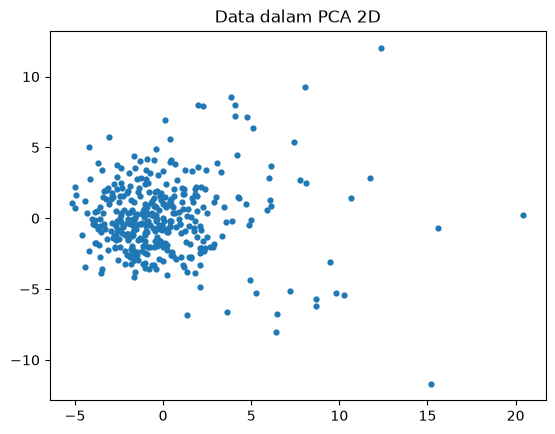

In [4]:
X = data.drop(columns=[LABEL_COL])
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca = PCA(n_components=2)
X_2d = pca.fit_transform(X_scaled)
plt.scatter(X_2d[:, 0], X_2d[:, 1], s=12)
plt.title("Data dalam PCA 2D")
plt.show()

## Langkah 2 — model anomali
Pilih SATU model: hapus `#` di depan baris yang ingin dipakai, beri `#` pada baris lain.
Semua model `pyod` dipakai dengan cara yang sama: `model.fit(X)`, lalu
`model.decision_function(X)` = skor dan `model.labels_` = tanda (1 = anomali).

ditandai anomali: 23 dari 379


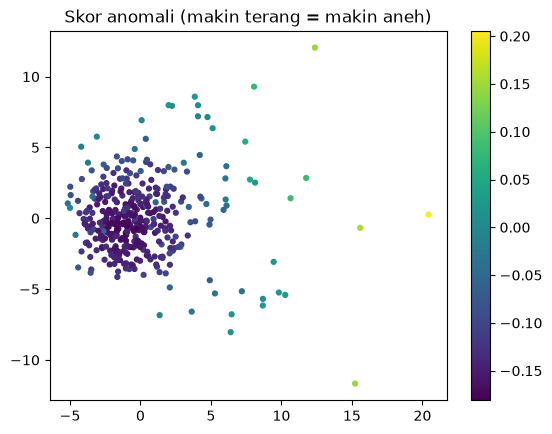

In [5]:
model = IForest(n_estimators=300, contamination=ANOMALY_FRACTION, random_state=SEED)
# model = LOF(n_neighbors=20, contamination=ANOMALY_FRACTION)    # kepadatan tetangga
# model = KNN(n_neighbors=10, contamination=ANOMALY_FRACTION)    # jarak ke tetangga terdekat
# model = OCSVM(contamination=ANOMALY_FRACTION)                  # batas di sekitar data normal
# model = ECOD(contamination=ANOMALY_FRACTION)                   # tanpa parameter, sangat cepat
# model = COPOD(contamination=ANOMALY_FRACTION)                  # tanpa parameter, sangat cepat
# model = HBOS(contamination=ANOMALY_FRACTION)                   # histogram per feature

model.fit(X_scaled)
scores = model.decision_function(X_scaled)
flags = model.labels_
print("ditandai anomali:", flags.sum(), "dari", len(flags))

plt.scatter(X_2d[:, 0], X_2d[:, 1], c=scores, cmap="viridis", s=12)
plt.title("Skor anomali (makin terang = makin aneh)")
plt.colorbar()
plt.show()

## Langkah 3 — simpan skor

In [6]:
submission = pd.DataFrame()
submission["anomaly_score"] = scores
submission["is_anomaly"] = flags
submission.to_csv("submission.csv", index=False)
submission.head()

,anomaly_score,is_anomaly
0,-0.142863,0
1,-0.155443,0
2,-0.168364,0
3,-0.126043,0
4,-0.161751,0


## Cek dengan kunci jawaban (HAPUS saat lomba)
AUC = seberapa sering anomali diberi skor lebih tinggi dari baris normal (1 = sempurna).
AP = presisi rata-rata (cocok bila anomali sedikit).

In [7]:
truth = data[LABEL_COL]
print("AUC:", round(roc_auc_score(truth, scores), 3))
print("AP :", round(average_precision_score(truth, scores), 3))
print("F1 anomali:", round(f1_score(truth, flags), 3))

AUC: 0.953
AP : 0.6
F1 anomali: 0.578
